In [5]:
import json
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [25]:
def SES_measurement(T_obs, dist_null, nperm=999):
    SES_numerator = T_obs - np.mean(dist_null)
    SES_denominator = np.std(dist_null)

    SES_value = SES_numerator/SES_denominator

    return SES_value


def p_value_double(T_obs, dist_null, nperm=999):
    p_numerator = 1

    T_null_mean = np.mean(dist_null)

    for i in range(len(dist_null)):
        if np.abs(dist_null[i]-T_null_mean) >= np.abs(T_obs - T_null_mean):
            p_numerator += 1

    p_value = p_numerator/(1+nperm)

    return p_value

def relative_effect_measurements(T_obs, dist_null):
    return (T_obs - np.mean(dist_null))/np.mean(dist_null)

## Evaluate method

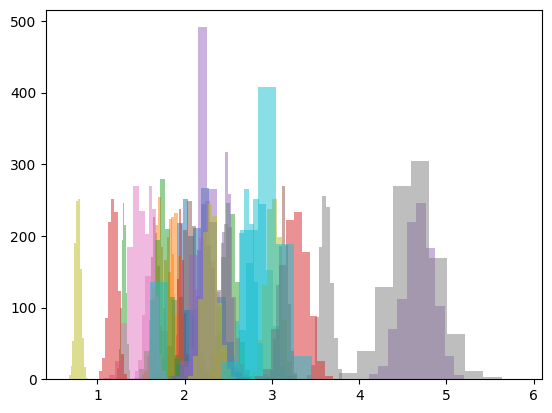

In [27]:
f_path = r"Z:\Emma\Chanthirika_CD8_CAF\full_distributions"

domains = [d for d in os.listdir(f_path) if d.endswith(".csv")]
distributions = [n for n in os.listdir(f_path) if n.endswith(".json")]

for i in range(len(domains)):
    domain = domains[i]

    with open(os.path.join(f_path, distributions[i])) as f:
            null_dists = json.load(f)

    # Find Tobs from raw distances
    df = pd.read_csv(os.path.join(f_path,domain))
    df = df.loc[df["Phenotype"] == "CD8"]

    raw_distances = np.array(df[['CD8_to_PDGFRa: PDPN', 'CD8_to_PDGFRa: PDPN: FAP', 'CD8_to_PDGFRa: PDPN: aSMA', 'CD8_to_PDGFRa: PDPN: FAP: aSMA']])
    raw_distances_min = np.min(raw_distances, axis=1)
    T_obs = np.mean(raw_distances_min)

    SES_values = []
    for key in null_dists:
        null_dist = null_dists[key]

        SES_values.append(SES_measurement(T_obs, null_dist))
    
    plt.hist(SES_values, alpha=0.5)

plt.savefig(os.path.join(r"Z:\Emma\Chanthirika_CD8_CAF\histograms", "SES_median_histogram.png"))
    


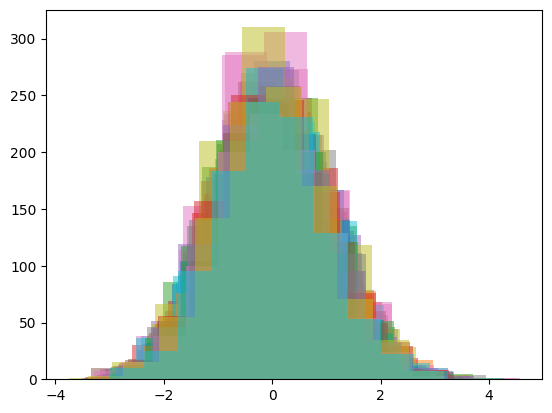

In [26]:
path = r"Z:\Emma\Chanthirika_CD8_CAF\nearestneighbour"

null_dists = [n for n in os.listdir(path) if n.endswith(".json")]



for i in range(len(null_dists)):
    with open(os.path.join(path, distributions[i])) as f:
            null_dist = json.load(f)

    for key in null_dist:
        if key.endswith("anyCAF"):
                data = null_dist[key]
        else:
            continue    

    T_null = np.mean(data)
    std_null = np.std(data)
    SES_values = []

    for d in data:
        SES_values.append((d-T_null)/std_null)

    plt.hist(SES_values, alpha = 0.5)

    plt.savefig(os.path.join(r"Z:\Emma\Chanthirika_CD8_CAF\histograms", f"SES_histogram_{i}_.png"))


## Analysis A

### Is Class A cells associated with subtype X of Class B specifically, given X's own density?

Calculate SES and p-values for each Class A - subtype X individually, eg CD8 to CAF+, CD8 to CAF+FAP+, CD8 to CAF+aSMA+ and CD8 to CAF+FAP+asMA+.
Each pair has it's own null distribution.

The density of Class A and Class B and their X and Y coordinates have been perserved, however, the labels have been shuffled around all cells. E.g., All CD8 and CAF cells are found and their absolute numbers saved. The labels for these cells are then shuffled around, so some CD8 cells are now being labelled as CAF and vice versa, and some are left unchanged.

In [ ]:
file_dir = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\nearestneighbour"
obs_file_dir = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\CD8_to_CAF"

output = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW"

domains = sorted([d for d in os.listdir(obs_file_dir) if d.endswith(".csv")])
files = sorted([f for f in os.listdir(file_dir) if f.endswith(".json")])

not_processed = []

results = []
results_index = []

for i in range(len(domains)):
    domain = domains[i]
    file = files[i]

    domain_name = domain[:-21]

    if file.index(domain_name) == -1:
        print(f"Not processing {domain_name}")
        not_processed.append(domain)
        continue

    with open(os.path.join(file_dir, file)) as f:
        cur_data = json.load(f)

    subtypes = [k[k.rfind("_")+1:] for k in cur_data.keys()]

    df = pd.read_csv(os.path.join(obs_file_dir, domain))
    df = df.rename(columns={"CD8_to_any_CAF": "CD8_to_anyCAF"})
    df.to_csv(os.path.join(obs_file_dir, domain), index=False)
    columns = df.columns.tolist()
    column_start = columns[1][:columns[1].rfind("_")+1]

    for s in subtypes:
        cur_df = df[column_start+s]

        cur_T_obs = np.mean(cur_df.values)

        cur_dist_null = cur_data[f"{domain_name}_{s}"] if f"{domain_name}_{s}" in cur_data.keys() else cur_data[f"{domain_name}.csv_{s}"]

        SES_value = SES_measurement(cur_T_obs, cur_dist_null)
        p_value = p_value_double(cur_T_obs, cur_dist_null)
        rel_eff = relative_effect_measurements(cur_T_obs, cur_dist_null)

        print(f"For {s}; SES value: {SES_value}, p value: {p_value}, Relative effect: {rel_eff}")

        results.append([SES_value, p_value, rel_eff, cur_T_obs, np.mean(cur_dist_null), np.std(cur_dist_null)])
        results_index.append(f"{domain_name}_{column_start}{s}")

    results_df = pd.DataFrame(results, index=results_index, columns=["SES", "p", "Rel. Effect", "Observed distance [um]", "Null distance[um]", "Null std distance [um]"])
    results_df.to_csv(os.path.join(output, "nearestneighbour_SES_measurements.csv"))

['PDGFRa: PDPN', 'PDGFRa: PDPN: FAP', 'PDGFRa: PDPN: aSMA', 'PDGFRa: PDPN: FAP: aSMA', 'anyCAF']
['Unnamed: 0', 'CD8_to_PDGFRa: PDPN', 'CD8_to_PDGFRa: PDPN: FAP', 'CD8_to_PDGFRa: PDPN: aSMA', 'CD8_to_PDGFRa: PDPN: FAP: aSMA', 'CD8_to_anyCAF', 'CAF_type_min']
['PDGFRa: PDPN', 'PDGFRa: PDPN: FAP', 'PDGFRa: PDPN: aSMA', 'PDGFRa: PDPN: FAP: aSMA', 'anyCAF']
['Unnamed: 0', 'CD8_to_PDGFRa: PDPN', 'CD8_to_PDGFRa: PDPN: FAP', 'CD8_to_PDGFRa: PDPN: aSMA', 'CD8_to_PDGFRa: PDPN: FAP: aSMA', 'CD8_to_anyCAF', 'CAF_type_min']
['PDGFRa: PDPN', 'PDGFRa: PDPN: FAP', 'PDGFRa: PDPN: aSMA', 'PDGFRa: PDPN: FAP: aSMA', 'anyCAF']
['Unnamed: 0', 'CD8_to_PDGFRa: PDPN', 'CD8_to_PDGFRa: PDPN: FAP', 'CD8_to_PDGFRa: PDPN: aSMA', 'CD8_to_PDGFRa: PDPN: FAP: aSMA', 'CD8_to_anyCAF', 'CAF_type_min']
['PDGFRa: PDPN', 'PDGFRa: PDPN: FAP', 'PDGFRa: PDPN: aSMA', 'PDGFRa: PDPN: FAP: aSMA', 'anyCAF']
['Unnamed: 0', 'CD8_to_PDGFRa: PDPN', 'CD8_to_PDGFRa: PDPN: FAP', 'CD8_to_PDGFRa: PDPN: aSMA', 'CD8_to_PDGFRa: PDPN: FAP: aSMA

In [55]:
results_df

,SES,p,Rel. Effect,Observed distance [um],Null distance[um],Null std distance [um]
MP26_38_CR1_Scan1_muspan_1390102_CD8_to_PDGFRa: PDPN,176.949593,0.001,1.790449,49.342042,17.682472,0.178919
MP26_38_CR1_Scan1_muspan_1390102_CD8_to_PDGFRa: PDPN: FAP,56.037877,0.001,0.881834,107.353759,57.047402,0.897721
MP26_38_CR1_Scan1_muspan_1390102_CD8_to_PDGFRa: PDPN: aSMA,161.377830,0.001,1.539669,37.644072,14.822430,0.141417
MP26_38_CR1_Scan1_muspan_1390102_CD8_to_PDGFRa: PDPN: FAP: aSMA,59.531918,0.001,0.813683,75.577548,41.670769,0.569556
MP26_38_CR1_Scan1_muspan_1390102_CD8_to_anyCAF,180.649120,0.001,1.465257,28.522992,11.569985,0.093845
...,...,...,...,...,...,...
MP26_38_CR5_Scan1_muspan_No dox-72h_CD8_to_PDGFRa: PDPN,196.570667,0.001,3.999835,71.180784,14.236627,0.289688
MP26_38_CR5_Scan1_muspan_No dox-72h_CD8_to_PDGFRa: PDPN: FAP,49.771488,0.001,1.259982,174.255480,77.104806,1.951934
MP26_38_CR5_Scan1_muspan_No dox-72h_CD8_to_PDGFRa: PDPN: aSMA,91.134859,0.001,1.585149,44.170500,17.086250,0.297189
MP26_38_CR5_Scan1_muspan_No dox-72h_CD8_to_PDGFRa: PDPN: FAP: aSMA,80.224222,0.001,1.669672,144.913406,54.281349,1.129734


## Analysis B

### Given Class A is near some Class B cells, is the specific subtype it lands next to non-random?

Calculate the SES and p-value for the proportions of subtypes in Class B that are closest to the Class A cells.

Here, the Class A cells have been locked and the labels for Class B cells are shuffled around. E.g., the counts for the different subtype of CAFs (CAF+, CAF+FAP+, CAF+aSMA+, CAF+FAP+aSMA+) have been preserved but the labels for these cells are shuffled around, so that the proportion of CD8 cells that are closest to a CAF+ cell varies with the shuffling. The SES and p values are then a measure of if the observed proportions are higher or lower than a random shuffling of the cells.



In [57]:
file_dir = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\analysisB_nearestneighbour"
obs_file_dir = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\CD8_to_CAF"

output = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW"

domains = sorted([d for d in os.listdir(obs_file_dir) if d.endswith(".csv")])
files = sorted([f for f in os.listdir(file_dir) if f.endswith(".json")])

not_processed = []

results = []
results_index = []

for i in range(len(domains)):
    domain = domains[i]
    file = files[i]

    domain_name = domain[:-21]

    if file.index(domain_name) == -1:
        print(f"Not processing {domain_name}")
        not_processed.append(domain)
        continue

    with open(os.path.join(file_dir, file)) as f:
        cur_data = json.load(f)

    subtypes = [k[k.rfind("_")+1:] for k in cur_data.keys()]

    df = pd.read_csv(os.path.join(obs_file_dir, domain))
    n_cells = len(df)

    columns = df.columns.tolist()
    column_start = columns[1][:columns[1].rfind("_")+1]

    for s in subtypes:
        cur_df = df.loc[df[columns[-1]] == s]

        cur_T_obs = len(cur_df)/n_cells

        cur_dist_null = cur_data[f"{domain_name}_nearestCAF_{s}"] if f"{domain_name}_{s}" in cur_data.keys() else cur_data[f"{domain_name}.csv_nearestCAF_{s}"]

        SES_value = SES_measurement(cur_T_obs, cur_dist_null)
        p_value = p_value_double(cur_T_obs, cur_dist_null)
        rel_eff = relative_effect_measurements(cur_T_obs, cur_dist_null)

        print(f"For {s}; SES value: {SES_value}, p value: {p_value}, Relative effect: {rel_eff}")

        results.append([SES_value, p_value, rel_eff, cur_T_obs, np.mean(cur_dist_null), np.std(cur_dist_null)])
        results_index.append(f"{domain_name}_{column_start}{s}")

    results_df = pd.DataFrame(results, index=results_index, columns=["SES", "p", "Rel. Effect", "Observed proportions", "Null proportions", "Null std proportions"])
    results_df.to_csv(os.path.join(output, "nearestneighbour_proportions_measurements.csv"))

For PDGFRa: PDPN; SES value: -13.301792594458858, p value: 0.001, Relative effect: -0.23972904963776448
For PDGFRa: PDPN: FAP; SES value: 1.979106433714275, p value: 0.044, Relative effect: 0.13096174088982393
For PDGFRa: PDPN: FAP: aSMA; SES value: 11.949405276845276, p value: 0.001, Relative effect: 0.6080564860446562
For PDGFRa: PDPN: aSMA; SES value: 5.65456284508233, p value: 0.001, Relative effect: 0.07273429289949476
For PDGFRa: PDPN; SES value: -28.82925014552261, p value: 0.001, Relative effect: -0.5606314317348768
For PDGFRa: PDPN: FAP; SES value: -2.5745323986379707, p value: 0.011, Relative effect: -0.18836408913670802
For PDGFRa: PDPN: FAP: aSMA; SES value: 22.01806452865289, p value: 0.001, Relative effect: 0.9534864527612544
For PDGFRa: PDPN: aSMA; SES value: 16.053425312665844, p value: 0.001, Relative effect: 0.15983547091806233
For PDGFRa: PDPN; SES value: -21.64100950703777, p value: 0.001, Relative effect: -0.16615599451586738
For PDGFRa: PDPN: FAP; SES value: -5.33

# Extract relevant data for plotting

### Chanthirika

In [59]:
path = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\CD8_to_CAF"
output = r"C:\Users\ewestlund\Documents\QuPath\Chanthirika_CAF-panel\Refined_classifications\muspan_output_KNN8_ex139_NEW\ViolinPlot_Distances"
domains = [d for d in os.listdir(path) if d.endswith(".csv")]

for domain in domains:
    df = pd.read_csv(os.path.join(path, domain))

    df = df[["CD8_to_anyCAF", "CAF_type_min"]]

    df.to_csv(os.path.join(output, domain.replace("_nearestneighbour.csv", "_violinplot.csv")))